# Tutorial 1 - Create your own national dispatch model in PyPSA

## 1. Importing the needed Python libraries and input data

In [1]:
import pandas as pd
import pypsa

### 1.1. Importing pre-downloaded electricity demand and renewables timeseries (in this example, for the NL)
While the PyPSA ecosystem includes tools to generate demand and renewables time series, they require extra steps that we prefer to skip in this project. Therefore, just download in advance demand and renewables time series from the open repositories indicated in the learning material.

In [2]:
electricity_demand = pd.read_csv('input_data/demand.csv', index_col=0)
electricity_demand.head()

,demand
time_utc,
2019-01-01 00:00:00,11194
2019-01-01 01:00:00,10933
2019-01-01 02:00:00,10667
2019-01-01 03:00:00,10413
2019-01-01 04:00:00,10441


In [3]:
renewables_capacity_factors = pd.read_csv('input_data/renewables.csv', index_col=0)

# Select the same year as the demand, since we have a longer period in the renewables data
renewables_capacity_factors = renewables_capacity_factors.loc['2019-01-01 00:00:00':'2019-12-31 23:00:00']
renewables_capacity_factors.head(10)

,solar_pv,wind_offshore,wind_onshore
time_utc,,,
2019-01-01 00:00:00,0.000,0.5815,0.4009
2019-01-01 01:00:00,0.000,0.6078,0.4290
2019-01-01 02:00:00,0.000,0.6329,0.4630
2019-01-01 03:00:00,0.000,0.7024,0.5017
2019-01-01 04:00:00,0.000,0.7250,0.5305
2019-01-01 05:00:00,0.000,0.7257,0.5427
2019-01-01 06:00:00,0.000,0.7130,0.5459
2019-01-01 07:00:00,0.000,0.6656,0.5253
2019-01-01 08:00:00,0.006,0.6109,0.5040


### 1.2 Import pre-generated data of power plants (see auxiliary tutorial)

In [4]:
technoecon_params = pd.read_csv('input_data/technoecon_params.csv', index_col=0)
technoecon_params

,fuel,VOM,efficiency,FOM,CO2 intensity,lifetime,investment,installed_capacity
ccgt,11.6278,5.8775,0.5600,3.3295,0.1980,25.0,1175506.7,17470.5
solar,0.0000,0.0134,0.0000,1.5780,0.0000,35.0,1018204.4,7366.1
wind-onshore,0.0000,2.0037,0.0000,1.2514,0.0000,27.0,1494463.1,5505.8
wind-offshore,0.0000,0.0267,0.0000,2.5093,0.0000,27.0,2505378.1,7138.0
nuclear,7.4536,4.4590,0.3260,1.2700,0.0000,40.0,10805703.8,515.0
battery,0.0000,0.0000,0.9500,0.2000,0.0000,15.0,1601785.4,263.4
biomass,9.3506,2.8138,0.2994,3.6081,NaN,25.0,4516713.3,1573.2
coal,7.8202,4.1005,0.3560,1.3100,0.3361,40.0,4812024.4,6007.0


## 2. Creating a model ('Network')

In [5]:
n = pypsa.Network()

# Define the time resolution of the model, typically a full year with hourly timesteps (it should match your inputs).
n.set_snapshots(pd.date_range(start='2019-01-01', end='2019-12-31 23:00:00', freq='h'))
# Check that it's correct
n.snapshots

/home/fl/Nextcloud/Teaching_material/SEN1522/2026/pypsa-sen1522/.pixi/envs/default/lib/python3.15/site-packages/pypsa/network/io.py:2079: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)


DatetimeIndex(['2019-01-01 00:00:00', '2019-01-01 01:00:00',
               '2019-01-01 02:00:00', '2019-01-01 03:00:00',
               '2019-01-01 04:00:00', '2019-01-01 05:00:00',
               '2019-01-01 06:00:00', '2019-01-01 07:00:00',
               '2019-01-01 08:00:00', '2019-01-01 09:00:00',
               ...
               '2019-12-31 14:00:00', '2019-12-31 15:00:00',
               '2019-12-31 16:00:00', '2019-12-31 17:00:00',
               '2019-12-31 18:00:00', '2019-12-31 19:00:00',
               '2019-12-31 20:00:00', '2019-12-31 21:00:00',
               '2019-12-31 22:00:00', '2019-12-31 23:00:00'],
              dtype='datetime64[us]', name='snapshot', length=8760, freq='h')

### 2.1 Initialising the technology groups (or 'carriers') in the model
Let's ignore batteries for now, since their capacity is rather small for the 2019 data we are using

In [6]:
n.add("Carrier", 
      name="ccgt", 
      co2_emissions=technoecon_params.loc['ccgt','CO2 intensity'], # 0.198 tonnes/MWh
      color='dimgrey' 
     )
n.add("Carrier", 
      name="coal", 
      co2_emissions=technoecon_params.loc['coal','CO2 intensity'], # 0.336 tonnes/MWh
      color='saddlebrown' 
     )
n.add("Carrier", name="electricity", color='darksalmon')
n.add("Carrier", name="solar", color='orange')
n.add("Carrier", name="wind-onshore", color='lightseagreen')
n.add("Carrier", name="wind-offshore", color='royalblue')
n.add("Carrier", name="nuclear", color='crimson')
n.add("Carrier", name="biomass", color='green')
n.add("Carrier", name="lost-load", color='black')

### 2.2 Adding a node (or 'Bus'), a demand and some generators
We use only a single node to represent the whole country. For now, we only include a few generators. 

In [7]:
# Single electricity node/bus
n.add("Bus", "electricity", carrier="electricity")

# Electricity demand
n.add(
    "Load",
    "demand",
    bus="electricity",
    carrier="electricity",
    p_set=electricity_demand['demand'].values,
)

# Solar generators
n.add(
    "Generator",
    "solar",
    bus="electricity",
    carrier="solar",
    p_max_pu=renewables_capacity_factors['solar_pv'].values,
    marginal_cost=technoecon_params.loc['solar','VOM'],
    p_nom=technoecon_params.loc['solar','installed_capacity'],
)

# On-shore wind generators
n.add(
    "Generator",
    "wind-onshore",
    bus="electricity",
    carrier="wind-onshore",
    p_max_pu=renewables_capacity_factors['wind_onshore'].values,
    marginal_cost=technoecon_params.loc['wind-onshore','VOM'],
    p_nom=technoecon_params.loc['wind-onshore','installed_capacity'],
)

# Off-shore wind generators
n.add(
    "Generator",
    "wind-offshore",
    bus="electricity",
    carrier="wind-offshore",
    p_max_pu=renewables_capacity_factors['wind_offshore'].values,
    marginal_cost=technoecon_params.loc['wind-offshore','VOM'],
    p_nom=technoecon_params.loc['wind-offshore','installed_capacity'],
)

# Dispatchable gas power plants (Combined-Cycle Gas Turbines, or CCGTs)
n.add(
    "Generator",
    "ccgt",
    bus="electricity",
    carrier="ccgt",
    marginal_cost=(technoecon_params.loc['ccgt','VOM'] + technoecon_params.loc['ccgt','fuel']/technoecon_params.loc['ccgt','efficiency']),
    efficiency=technoecon_params.loc['ccgt','efficiency'],
    p_nom=technoecon_params.loc['ccgt','installed_capacity'],
)

# Dispatchable coal power plants 
n.add(
    "Generator",
    "coal",
    bus="electricity",
    carrier="coal",
    marginal_cost=(technoecon_params.loc['coal','VOM'] + technoecon_params.loc['coal','fuel']/technoecon_params.loc['coal','efficiency']),
    efficiency=technoecon_params.loc['coal','efficiency'],
    p_nom=technoecon_params.loc['coal','installed_capacity'],
    ramp_limit_up=0.6, # Assumption
    ramp_limit_down=0.6,
)

# Dispatchable biomass & waste power plants 
n.add(
    "Generator",
    "biomass",
    bus="electricity",
    carrier="biomass",
    marginal_cost=(technoecon_params.loc['biomass','VOM'] + technoecon_params.loc['biomass','fuel']/technoecon_params.loc['biomass','efficiency']),
    efficiency=technoecon_params.loc['biomass','efficiency'],
    p_nom=technoecon_params.loc['biomass','installed_capacity'],
)

# Nuclear power plants 
n.add(
    "Generator",
    "nuclear",
    bus="electricity",
    carrier="nuclear",
    marginal_cost=(technoecon_params.loc['nuclear','VOM'] + technoecon_params.loc['nuclear','fuel']/technoecon_params.loc['nuclear','efficiency']),
    efficiency=technoecon_params.loc['nuclear','efficiency'],
    p_nom=technoecon_params.loc['nuclear','installed_capacity'],
    ramp_limit_up=0.6, # Assumption
    ramp_limit_down=0.6,
)

# Dummy power plant to represent lost-load, when nothing else can generate power
n.add(
    "Generator",
    "lost-load",
    bus="electricity",
    carrier="lost-load",
    marginal_cost=150, # Substantially more expensive than anything else, but same order of magnitude
    efficiency=1,
    p_nom=18000 # Roughly same as peak load,
)

n.optimize()

/tmp/ipykernel_30410/2849318087.py:105: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize()
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|█████████████| 1/1 [00:00<00:00, 70.18it/s]
INFO:linopy.io: Writing time: 0.23s


Running HiGHS 1.15.1 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-4bxt2u72 has 183956 rows; 70080 cols; 280312 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+00]
  Cost    [1e-02, 2e+02]
  Bound   [0e+00, 0e+00]
  RHS     [6e-01, 2e+04]
Presolving model
43796 rows, 48312 cols, 118384 nonzeros 0s
19875 rows, 25952 cols, 48182 nonzeros 0s
Dependent equations search running on 2357 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
19875 rows, 25952 cols, 48182 nonzeros 0s
Presolve reductions: rows 19875(-164081); columns 25952(-44128); nonzeros 48182(-232130) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.5s
       2357     1.9661082955e+09 Pr: 0(0) 0.6s

Performed postsolve
Solving the orig

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 70080 primals, 289080 duals
Objective: 1.97e+09
Solver: highs
Runtime: 0.74s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p-ramp_limit_up, Generator-p-ramp_limit_down were not assigned to the network.



Model name          : linopy-problem-4bxt2u72
Model status        : Optimal
Simplex   iterations: 2357
Objective value     :  1.9661082955e+09
P-D objective error :  5.3174358272e-14
HiGHS run time      :          0.74


('ok', 'optimal')

## 3. Inspecting the results and extracting relevant KPIs

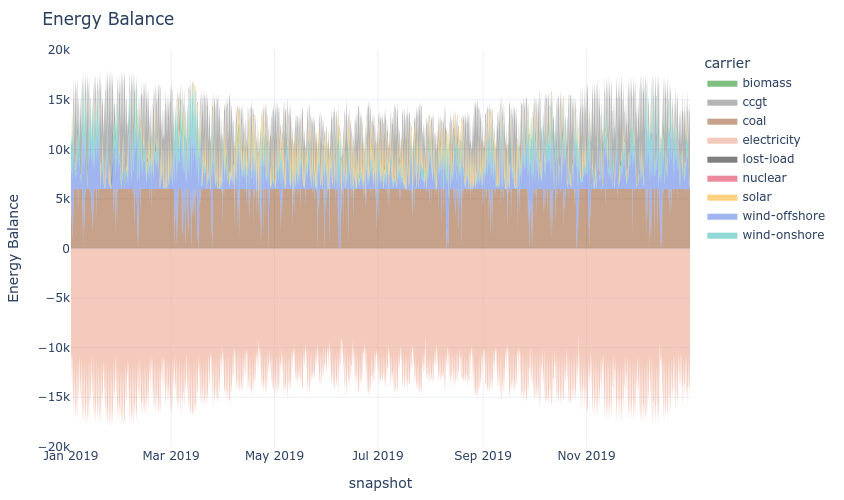

In [8]:
# Energy balance (i.e., plot of the cost-optimal dispatch)
n.statistics.energy_balance.iplot.area()

<Axes: title={'center': 'Price dynamics'}, xlabel='snapshot'>

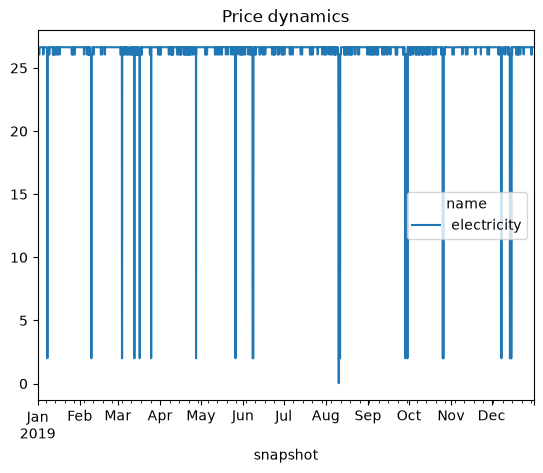

In [9]:
# Resulting electricity prices over time
n.buses_t.marginal_price.loc['2019-01-01':'2019-12-31'].plot(title="Price dynamics")

<Axes: >

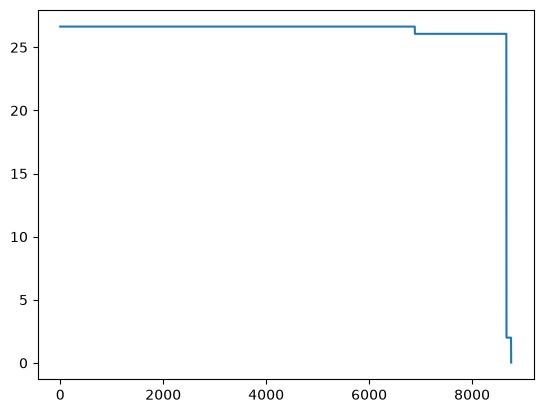

In [10]:
# The same prices as above, but visualised as a 'duration curve'
pdc = n.buses_t.marginal_price['electricity'].loc['2019-01-01':'2019-12-31'].sort_values(ascending=False).reset_index(drop=True)
pdc.plot()

<Axes: title={'center': 'Price dynamics'}, xlabel='snapshot'>

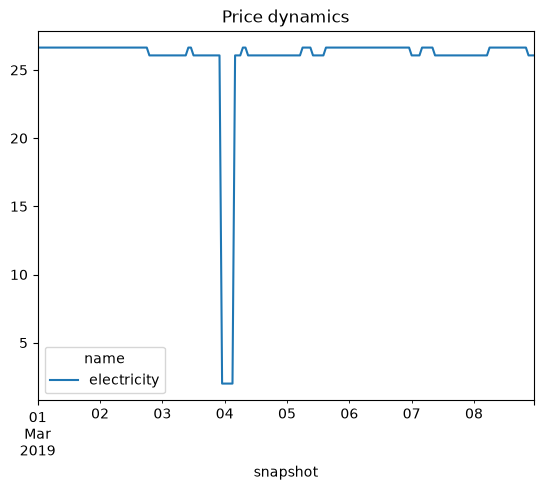

In [11]:
# Prices over time (zoom in on a given week)
n.buses_t.marginal_price.loc['2019-03-01':'2019-03-08'].plot(title="Price dynamics")

In [12]:
# Compare the prices with the marginal cost of each generator. 
# Which plant is dictating the price we see in the plot?
n.generators.marginal_cost

name
solar              0.013400
wind-onshore       2.003700
wind-offshore      0.026700
ccgt              26.641429
coal              26.067354
biomass           34.044929
nuclear           27.322804
lost-load        150.000000
Name: marginal_cost, dtype: float64

In [13]:
# Revenues, i.e. 
n.statistics.revenue() /1e6 # from Euros to Millions of Euros

component  carrier      
Generator  ccgt              682.253232
           coal             1283.878902
           solar             211.595608
           wind-offshore     520.598521
           wind-onshore      296.857227
Load       electricity     -2995.183491
dtype: float64

In [14]:
n.generators.p_nom['ccgt']

np.float64(17470.5)

In [15]:
# Simplified (i.e., no discount rate) cost recovery example
total_investment = (technoecon_params['investment']*n.generators.p_nom).dropna() # As long as tech names are the same
yearly_revenues = n.statistics.revenue(carrier=total_investment.index).droplevel("component")
payback_time = total_investment/yearly_revenues
payback_time

biomass                NaN
ccgt             30.101272
coal             22.514453
nuclear                NaN
solar            35.445894
wind-offshore    34.351594
wind-onshore     27.717752
dtype: float64

In [16]:
n.statistics.revenue(groupby_time=False, components=['Generator']).fillna(0)

snapshot                 2019-01-01 00:00:00  2019-01-01 01:00:00  \
component carrier                                                   
Generator biomass                    0.00000              0.00000   
          ccgt                       0.00000              0.00000   
          coal                  126061.14440         110330.99830   
          lost-load                  0.00000              0.00000   
          nuclear                    0.00000              0.00000   
          solar                      0.00000              0.00000   
          wind-offshore         108198.99113         113092.59985   
          wind-onshore           57537.82439          61570.78239   

snapshot                 2019-01-01 02:00:00  2019-01-01 03:00:00  \
component carrier                                                   
Generator biomass                    0.00000              0.00000   
          ccgt                       0.00000              0.00000   
          coal                   93847.02030          68739.84536   
          lost-load                  0.00000              0.00000   
          nuclear                    0.00000              0.00000   
          solar                      0.00000              0.00000   
          wind-offshore         117762.92603         130694.70571   
          wind-onshore           66450.51806          72004.80542   

snapshot                 2019-01-01 04:00:00  2019-01-01 05:00:00  \
component carrier                                                   
Generator biomass                    0.00000              0.00000   
          ccgt                       0.00000              0.00000   
          coal                   61131.15386          65219.36580   
          lost-load                  0.00000              0.00000   
          nuclear                    0.00000              0.00000   
          solar                      0.00000              0.00000   
          wind-offshore         134899.85997         135030.10811   
          wind-onshore           76138.22858          77889.19255   

snapshot                 2019-01-01 06:00:00  2019-01-01 07:00:00  \
component carrier                                                   
Generator biomass                    0.00000              0.00000   
          ccgt                       0.00000              0.00000   
          coal                   73092.59402          91698.44629   
          lost-load                  0.00000              0.00000   
          nuclear                    0.00000              0.00000   
          solar                      0.00000              0.00000   
          wind-offshore         132667.03470         123847.37489   
          wind-onshore           78348.46179          75391.91606   

snapshot                 2019-01-01 08:00:00  2019-01-01 09:00:00  ...  \
component carrier                                                  ...   
Generator biomass                    0.00000              0.00000  ...   
          ccgt                       0.00000              0.00000  ...   
          coal                  111653.67148         127481.69320  ...   
          lost-load                  0.00000              0.00000  ...   
          nuclear                    0.00000              0.00000  ...   
          solar                   1152.08841           9984.76626  ...   
          wind-offshore         113669.41304         103565.87870  ...   
          wind-onshore           72334.90519          67526.93034  ...   

snapshot                 2019-12-31 14:00:00  2019-12-31 15:00:00  \
component carrier                                                   
Generator biomass                    0.00000              0.00000   
          ccgt                  188817.72289         210855.85841   
          coal                  160035.06143         160035.06143   
          lost-load                  0.00000              0.00000   
          nuclear                    0.00000              0.00000   
          so

In [17]:
n.statistics.market_value(components='Generator')

carrier
biomass                NaN
ccgt             26.641429
coal             26.558644
lost-load              NaN
nuclear                NaN
solar            25.920481
wind-offshore    25.681235
wind-onshore     25.777247
dtype: float64

## 4. Export your model to Excel

In [18]:
n.export_to_excel("output_data/saved_model.xlsx")

INFO:pypsa.network.io:Exported network 'Unnamed Network' saved to 'output_data/saved_model.xlsx contains: sub_networks, carriers, generators, loads, buses
